Test samples: 1999
sentiment
Positive    1434
Negative     336
Neutral      229
Name: count, dtype: int64


Map: 100%|██████████| 1999/1999 [00:00<00:00, 13509.59 examples/s]
c:\Users\USER\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



BERT Test Accuracy: 0.8189

Classification Report:

              precision    recall  f1-score   support

    Negative       0.79      0.59      0.68       336
     Neutral       0.41      0.34      0.37       229
    Positive       0.87      0.95      0.91      1434

    accuracy                           0.82      1999
   macro avg       0.69      0.63      0.65      1999
weighted avg       0.81      0.82      0.81      1999



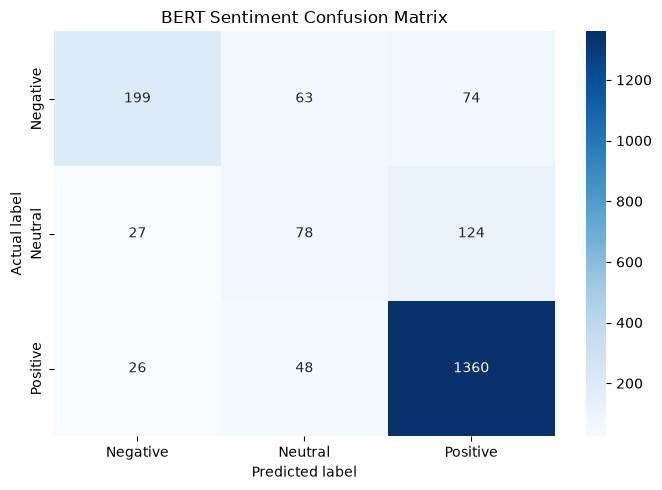

,clean_text,sentiment,predicted_sentiment,correct
0,nice phone full keyboard great price wife star...,Positive,Positive,True
1,last went nd day using thought ipod charge lcd,Negative,Negative,True
2,buy trick recommend follow instruction careful...,Positive,Positive,True
3,great super cute durable kept phone safe iphon...,Positive,Positive,True
4,work son insisted gave oredered shut noticable...,Negative,Neutral,False
5,bt speakerphone excellent basic feature actual...,Positive,Positive,True
6,use rechargables annoying light expensive batt...,Negative,Positive,False
7,great device bought one home liked much bought...,Positive,Positive,True
8,good please stop bugging every day stop buying...,Positive,Positive,True
9,avoid product another plantronics blue tooth h...,Negative,Negative,True


In [51]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import Dataset
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from transformers import AutoModelForSequenceClassification, AutoTokenizer, Trainer

# Project paths
PROJECT_ROOT = Path(r"D:\My_Project\Analyse\mobile-review-sentiment-analysis")
TEST_FILE = PROJECT_ROOT / "data" / "processed" / "test.csv"
MODEL_PATH = PROJECT_ROOT / "models" / "bert_sentiment"

# Sentiment class mapping used when training the model
label2id = {
    "Negative": 0,
    "Neutral": 1,
    "Positive": 2,
}
id2label = {
    0: "Negative",
    1: "Neutral",
    2: "Positive",
}
class_names = ["Negative", "Neutral", "Positive"]

# Load test data
test_df = pd.read_csv(TEST_FILE)

# Ensure required columns have valid values
test_df = test_df.dropna(subset=["clean_text", "sentiment"]).copy()
test_df["clean_text"] = test_df["clean_text"].astype(str)
test_df["label"] = test_df["sentiment"].map(label2id)

if test_df["label"].isna().any():
    invalid = test_df.loc[test_df["label"].isna(), "sentiment"].unique()
    raise ValueError(f"Unexpected sentiment values found: {invalid}")

test_df["label"] = test_df["label"].astype(int)

print(f"Test samples: {len(test_df)}")
print(test_df["sentiment"].value_counts())

# Load the trained BERT model and tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)
bert_model = AutoModelForSequenceClassification.from_pretrained(MODEL_PATH)

# Create Hugging Face dataset
test_dataset = Dataset.from_pandas(
    test_df[["clean_text", "label"]],
    preserve_index=False
)

# Tokenize test reviews
def tokenize_function(examples):
    return tokenizer(
        examples["clean_text"],
        truncation=True,
        padding="max_length",
        max_length=128
    )

tokenized_test = test_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["clean_text"]
)

# Get model predictions
trainer = Trainer(model=bert_model)
prediction_output = trainer.predict(tokenized_test)

predicted_labels = np.argmax(prediction_output.predictions, axis=1)
actual_labels = test_df["label"].to_numpy()

# Evaluation metrics
accuracy = accuracy_score(actual_labels, predicted_labels)

print(f"\nBERT Test Accuracy: {accuracy:.4f}")

print("\nClassification Report:\n")
print(
    classification_report(
        actual_labels,
        predicted_labels,
        labels=[0, 1, 2],
        target_names=class_names,
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(
    actual_labels,
    predicted_labels,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("BERT Sentiment Confusion Matrix")
plt.tight_layout()
plt.show()

# Optional: inspect sample predictions
results_df = test_df[["clean_text", "sentiment"]].copy()
results_df["predicted_sentiment"] = [id2label[label] for label in predicted_labels]
results_df["correct"] = results_df["sentiment"] == results_df["predicted_sentiment"]

results_df.head(10)